## Understand how the tabular data impacts the results on average, not by looking at individual examples

In [15]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt

sys.path.append('../')

from evaluate import evaluate
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

In [16]:
#Wider jupyterlab
#from IPython.display import display, HTML
#display(HTML("<style>.container { width:70% !important; }</style>"))

In [17]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [18]:
classes = [ i for i in LABEL_MAPPING.keys()]

In [19]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")

In [20]:
np.unique(labels.loc[labels.split.isin([0,1,2])].driver, return_counts=True)


(array(['cocoa', 'coffee', 'forest plantation', 'forest regrowth',
        'mining', 'other', 'palm oil', 'pasture', 'rubber',
        'shifting agriculture', 'soy', 'urban'], dtype=object),
 array([3670,  314, 3194, 3080, 2788, 3337, 3393, 3151, 2102, 2871, 2905,
        3327]))

## Load models and their configs and dataloaders

In [21]:


models = {
    'faostat-static' : {
        'wandb_id' : 'mvnz51pc', 
    },     

    'faostat-dynamic' : {
        'wandb_id' : 'nq0z1lof', 
    }, 
    
    #'loc' : {
    #    'wandb_id' : '7nv1stm4', 
    #},     
    
    
    'deduce-static' : {
        'wandb_id' : '3ktqu3rn', 
    }, 
    
    'deduce-dynamic' : {
        'wandb_id' : '1cn9ftp1', 
    },
    #'goldman' : {
    #    'wandb_id' : 'jezpdfdf', 
    #}, 
    
    'img' : {
        'wandb_id' : 'ey2o6bq6',
    },
    
    'img+deduce-dynamic' : {
        'wandb_id' : '9bmoakj7',
    },
    
}

In [22]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
n_classes = 12
num_images = 4


In [23]:
#Load config & dataloader for each model
for key, value in models.items():
    _id = value['wandb_id']
    model_dir = os.path.join('../models_trained', _id)
    config_path = os.path.join(model_dir, 'config.json')
    with open(config_path) as source:
        config = json.loads(source.read())
        
    
    #This is just to update the paths because the paths specified in the configs at the time these models
    #were trained are not correct (i've moved the tabular data)
    config['data'] = {
        "annotation_file": "/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv",
        "image_folder": "/home/jan/Documents/EPFL/project_2/data/images/dataset_v4/55k/SR_four_images",
        "forestloss_folder": "/home/jan/Documents/EPFL/project_2/data/forestloss_tiles/dataset_v4",
        "faostat_data": "/home/jan/Documents/EPFL/project_2/data/tabular/faostat_2000_2020_dynamic.csv",
        "deduce_data": "/home/jan/Documents/EPFL/project_2/data/tabular/deduce_yearly.csv",
        "goldman_data": "/home/jan/Documents/EPFL/project_2/data/tabular/goldman.csv",
        "output_folder":  "models_trained/"
    }

        

    models[key]['config'] = config
    
    # fetch dataloaders
    dataloaders = dataloader.fetch_dataloader(
        ['val'], config)
    models[key]['val_dl'] = dataloaders['val']
    

    model = MultiModalDriverClassifier(n_classes,  **config)
    model = model.to(device)
    
    trained_model_path = f'../models_trained/{_id}/best.pt'

    _ = model.load_state_dict(torch.load(trained_model_path)['state_dict'])
    _ = model.eval()
    
    models[key]['model'] = model
    


In [24]:
#This should be the same
for key in models:
    print(models[key]['val_dl'].dataset.img_labels.shape)

(9977, 7)
(9977, 7)
(9977, 7)
(9977, 7)
(9977, 7)
(9977, 7)


In [25]:
df = models['faostat-static']['val_dl'].dataset.img_labels

df.sample(1).sampleid.values[0]

10283255

## Plot images with predictions 

In [26]:
def plot_image_with_tmf(data, tmf, label):
   
    fig, ax = plt.subplots(1,2, figsize=(10,8))
    img = data[:3, :, :].detach()
    img = img/0.25
    print(label)
    
    ax[0].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
    
    ax[0].set_xticks([])
    ax[0].set_yticks([])
    ax[1].imshow(tmf.numpy()  )

    fig.tight_layout()
    plt.show()


def plot_ts_with_tmf(data, tmf, label):
    
    n_images = data.shape[0]
    print("Ground truth: ", label)
    fig, ax = plt.subplots(1,n_images+1, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

    ax[n_images].imshow(tmf.numpy()  )

    fig.tight_layout()
    plt.show()
    
    
    

def plot_predictions(models_dict, classes):

    _x = np.arange(len(classes))  # the label locations
    fig, ax = plt.subplots(1,figsize=(16,10))
    
    num_models = len(models_dict)
    
    col_width = 0.8/num_models  # the total width is 1, using 0.9 to create some space between classes, divided by the n of models

    
    for i, model_name in enumerate(models_dict.keys()):
        
        offset = -0.35 + i*col_width #Starting at -0.45, each column should be next to previous one
        ax.bar(
            _x+offset, 
            models_dict[model_name]['probabilities'].squeeze(), 
            width=col_width, 
            #color='r',  
            align='center', 
            label=model_name)

    
    plt.xticks(_x, classes) 
    plt.tight_layout()
    plt.legend(bbox_to_anchor=(0.2, 1.05), ncol=5)
    plt.show()

In [27]:
np.set_printoptions(suppress=True) #suppress scientific notation for numpy


In [28]:
df.country.unique()

array(['Ecuador', 'Ghana', "Côte d'Ivoire", 'Colombia', 'Brazil',
       'Viet Nam', 'Indonesia', 'Australia', 'Guatemala',
       'Bolivia (Plurinational State of)', 'Papua New Guinea', 'Uganda',
       'Mexico', 'Cuba', 'Suriname', 'Malaysia', 'Thailand', 'Peru',
       'Myanmar', "Lao People's Democratic Republic", 'Philippines',
       'Cambodia', 'Democratic Republic of the Congo', 'Angola',
       'Central African Republic', 'India', 'Liberia', 'Kenya', 'Bhutan',
       'Bahamas', 'Sierra Leone', 'Bangladesh',
       'Venezuela (Bolivarian Republic of)', 'Guyana', 'Panama',
       'United Republic of Tanzania', 'Timor-Leste', 'Ethiopia', 'Guinea',
       'France', 'Haiti', 'Cameroon', 'Nicaragua', 'Burundi', 'Nigeria',
       'Paraguay', 'Congo', 'Gabon', 'Madagascar', 'Rwanda', 'Belize',
       'El Salvador', 'Costa Rica', 'Sri Lanka', 'Jamaica', 'South Sudan',
       'Mozambique'], dtype=object)

### Get the average of all predictions over Brazil for
- img only net
- img + tab net

In [29]:
models.keys()

dict_keys(['faostat-static', 'faostat-dynamic', 'deduce-static', 'deduce-dynamic', 'img', 'img+deduce-dynamic'])

In [46]:
for model_name in ['img', 'img+deduce-dynamic']:
    models[model_name]['probabilities'] = np.array([])

In [49]:

_df = df.loc[df.country == 'Brazil']

for idx, row in _df.iterrows():

    sampleid = df.iloc[idx].sampleid

    for model_name in ['img', 'img+deduce-dynamic']:
        _inputs, label = models[model_name]['val_dl'].dataset.__getitem__(idx)

        img, loc, tabular, forestloss = _inputs[0].unsqueeze(0).to(device), _inputs[1].unsqueeze(0).to(device), _inputs[2].unsqueeze(0).to(device), _inputs[3].unsqueeze(0).to(device)
        models[model_name]['inputs'] = img, loc, tabular, forestloss
        if model_name == 'img':
            images = img #Just to have an actual image and not an empty placeholder for plotting
        y_hat = models[model_name]['model'](img, loc, tabular, forestloss)
        
        class_probs = F.softmax(y_hat, dim=1).detach().cpu().numpy()
        if models[model_name]['probabilities'].size == 0:
            models[model_name]['probabilities'] = class_probs
        else:
            models[model_name]['probabilities'] = np.append(models[model_name]['probabilities'], class_probs, axis=0)


In [59]:
models['img+deduce-dynamic']['probabilities'].mean(axis=0)

array([0.23658162, 0.13571306, 0.29999128, 0.00585493, 0.00341035,
       0.07230894, 0.01606962, 0.00066216, 0.00233938, 0.12040885,
       0.00190583, 0.10475446], dtype=float32)

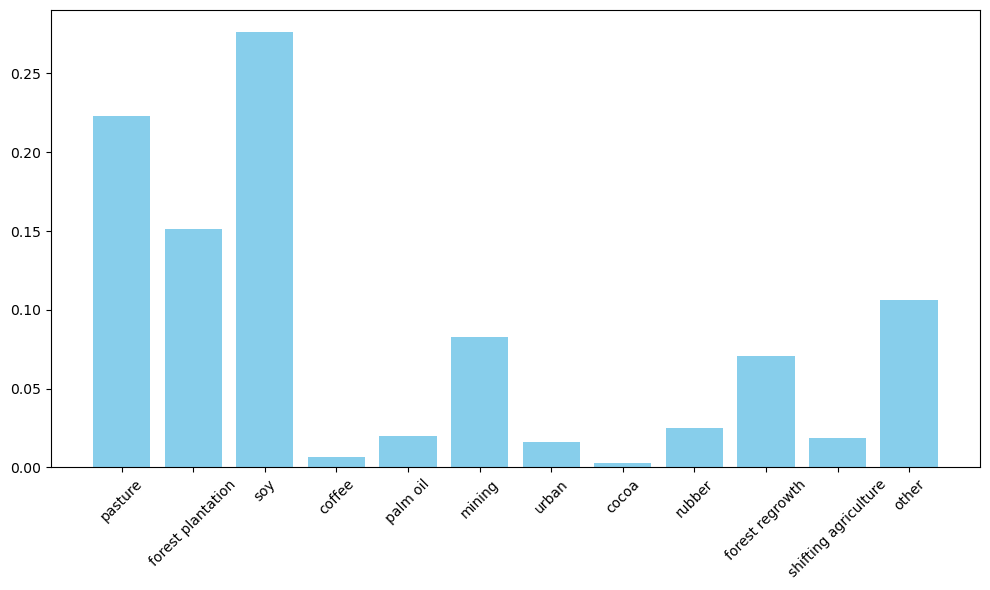

In [55]:

# Data
categories = ['pasture',
 'forest plantation',
 'soy',
 'coffee',
 'palm oil',
 'mining',
 'urban',
 'cocoa',
 'rubber',
 'forest regrowth',
 'shifting agriculture',
 'other']
img =[0.22323719, 0.15156738, 0.27642173, 0.00657854, 0.02015033,
       0.08292366, 0.01634909, 0.00259027, 0.02474397, 0.07065993,
       0.018368  , 0.10640937]

# Plotting the histogram
plt.figure(figsize=(10, 6))
plt.bar(categories, values, color='skyblue')
plt.xticks(rotation=45)
plt.tight_layout()

# Show the plot
plt.show()

In [64]:
ground_truth_probs = np.array([4982, 2723, 4989, 158, 30, 1380, 1170, 0, 0, 1764, 0, 1565])


In [65]:
ground_truth_probs/ground_truth_probs.max()

array([0.99859691, 0.54580076, 1.        , 0.03166967, 0.00601323,
       0.27660854, 0.23451594, 0.        , 0.        , 0.35357787,
       0.        , 0.31369012])

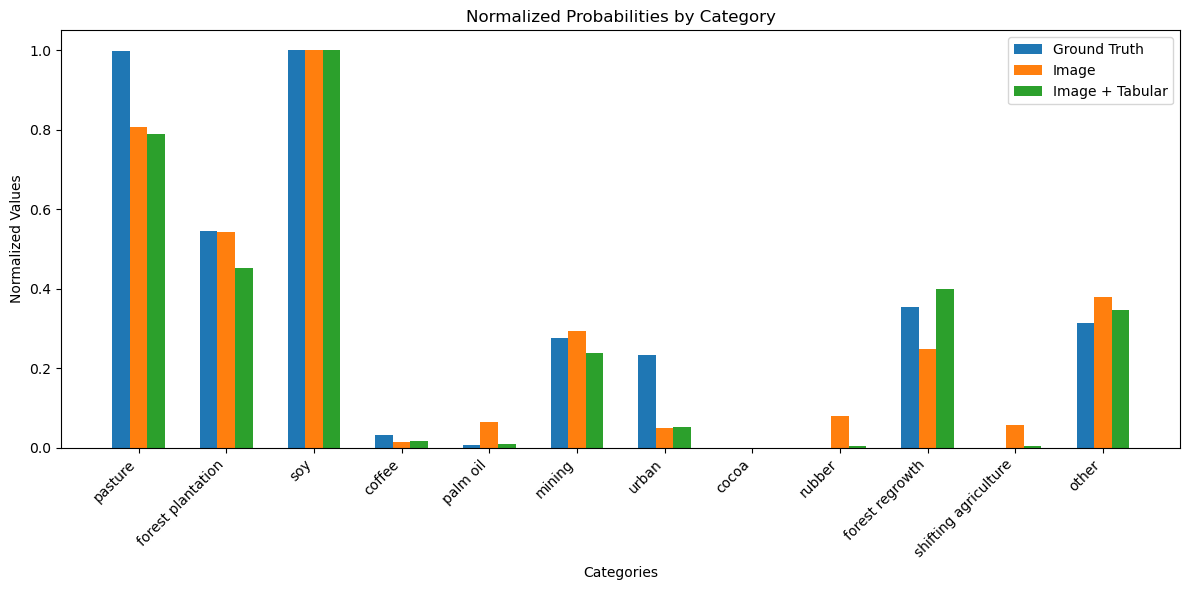

In [66]:
import numpy as np
import matplotlib.pyplot as plt

# Data
categories = ['pasture', 'forest plantation', 'soy', 'coffee', 'palm oil', 'mining', 'urban', 'cocoa', 'rubber', 'forest regrowth', 'shifting agriculture', 'other']
ground_truth_probs = [4982, 2723, 4989, 158, 30, 1380, 1170, 0, 0, 1764, 0, 1565]
img = [0.22323719, 0.15156738, 0.27642173, 0.00657854, 0.02015033, 0.08292366, 0.01634909, 0.00259027, 0.02474397, 0.07065993, 0.018368, 0.10640937]
img_tab = [0.23658162, 0.13571306, 0.29999128, 0.00585493, 0.00341035, 0.07230894, 0.01606962, 0.00066216, 0.00233938, 0.12040885, 0.00190583, 0.10475446]

# Normalize the arrays using Min-Max scaling
def normalize(array):
    min_val = min(array)
    max_val = max(array)
    return [(x - min_val) / (max_val - min_val) for x in array]

normalized_ground_truth_probs = normalize(ground_truth_probs)
normalized_img = normalize(img)
normalized_img_tab = normalize(img_tab)

# Plotting
x = np.arange(len(categories))
width = 0.2  # Width of the bars

fig, ax = plt.subplots(figsize=(12, 6))

bar1 = ax.bar(x - width, normalized_ground_truth_probs, width, label='Ground Truth')
bar2 = ax.bar(x, normalized_img, width, label='Image')
bar3 = ax.bar(x + width, normalized_img_tab, width, label='Image + Tabular')

# Add labels and title
ax.set_xlabel('Categories')
ax.set_xticks(x)
ax.set_xticklabels(categories, rotation=45, ha="right")
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

In [54]:
classes

['pasture',
 'forest plantation',
 'soy',
 'coffee',
 'palm oil',
 'mining',
 'urban',
 'cocoa',
 'rubber',
 'forest regrowth',
 'shifting agriculture',
 'other']

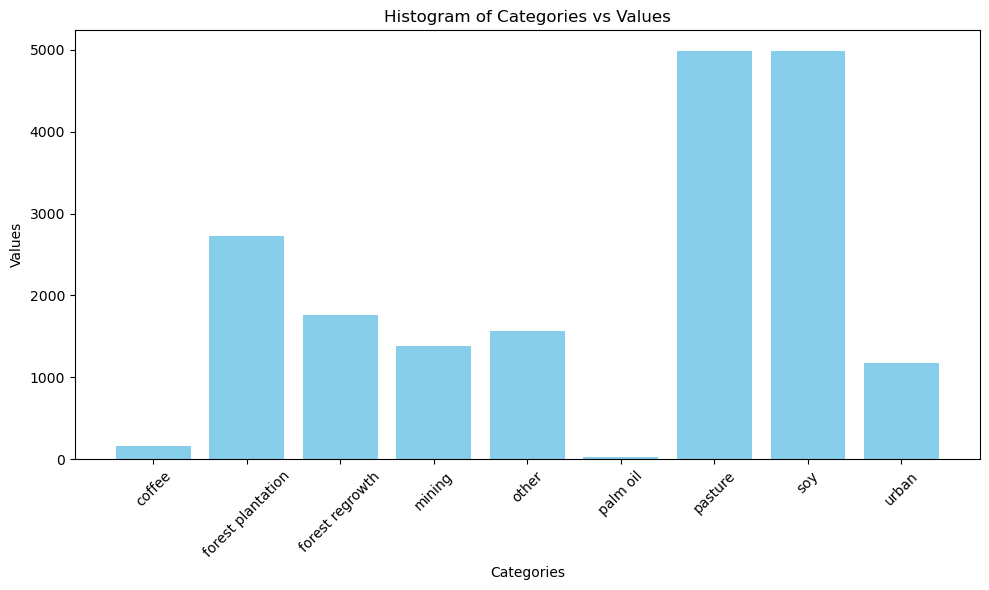

In [56]:
np.unique(labels.loc[labels.country == 'Brazil'].driver, return_counts=True)


import matplotlib.pyplot as plt

# Data
categories = ['coffee', 'forest plantation', 'forest regrowth', 'mining',
              'other', 'palm oil', 'pasture', 'soy', 'urban']
values = [158, 2723, 1764, 1380, 1565, 30, 4982, 4989, 1170]

# Plotting the histogram
plt.figure(figsize=(10, 6))
plt.bar(categories, values, color='skyblue')
plt.xlabel('Categories')
plt.ylabel('Values')
plt.title('Histogram of Categories vs Values')
plt.xticks(rotation=45)
plt.tight_layout()

# Show the plot
plt.show()

In [103]:
dynamic_df = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/tabular/faostat_2000_2020_dynamic.csv")


In [110]:
country_data = dynamic_df.loc[dynamic_df['country'] == 'Bolivia (Plurinational State of)']

In [112]:
tabular_column_names = ['Cattle', 'Soya beans', 'Cocoa beans', 'Coffee, green', 'Oil palm fruit', 'Natural rubber in primary forms']


In [114]:
_class = tabular_column_names[0]

In [115]:
production_at_the_start = country_data.loc[(country_data.Item == _class) & (country_data.Year == int(min_year)), 'Value' ].item()

In [116]:
production_at_the_start

0.2917127640677132

In [117]:
production_at_the_end = country_data.loc[(country_data.Item == _class) & (country_data.Year == int(max_year)), 'Value' ].item()


In [119]:
rate = production_at_the_end - production_at_the_start

In [120]:
rate

0.10750477557874222

In [124]:
def _get_dynamic_commodity_data(tab_data, country, forestloss_patch, tab_col_names): #TODO: Max year should be 2022, this is temporary

    years = forestloss_patch[(forestloss_patch >= 2000) & (forestloss_patch <= 2020)]
    try:
        min_year, max_year = years.min(), years.max()
        #TODO: consider using not the absolute min,max, but percentiles
        #min_year, max_year = np.percentile(years.flatten(), 10), np.percentile(years.flatten(), 90)
    except:
        min_year, max_year = 2000, 2020


    country_data = tab_data.loc[tab_data['country'] == country]

    rates = []
    for _class in tab_col_names:
        try:
            production_at_the_start = country_data.loc[(country_data.Item == _class) & (country_data.Year == int(min_year)), 'Value' ].item()
            production_at_the_end = country_data.loc[(country_data.Item == _class) & (country_data.Year == int(max_year)), 'Value' ].item()
            rate = production_at_the_end - production_at_the_start
        except ValueError: #Signifies that one (or both) of the values are missing
            rate = np.nan

        rates.append(rate)

    return np.array(rates)

In [126]:
rates = _get_dynamic_commodity_data(dynamic_df, 'Bolivia (Plurinational State of)', forestloss_patch, tabular_column_names)

In [128]:
tabular_cls_indices = torch.tensor([0, 2, 7, 3, 4, 8]) 

rates = np.nan_to_num(rates.astype('float32'), nan=0.0)
tabular_data = torch.zeros((12), dtype=torch.float)
tabular_data[tabular_cls_indices] = torch.Tensor(rates.squeeze())
tabular_data = torch.nan_to_num(tabular_data, nan=0.0)
tabular_data = tabular_data.squeeze()

In [129]:
tabular_data

tensor([ 0.1075,  0.0000,  0.4398, -0.0010,  0.0000,  0.0000,  0.0000,  0.0028,
        -0.0016,  0.0000,  0.0000,  0.0000])